[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sage-ai-group/learn-ml-by-building/blob/main/Lecture%200%20Environment%20Setup/00-Environment-Setup.ipynb)
# Machine Learning Development Environment Setup

## Understanding and Testing Your ML Development Stack

**Course:** Learn ML by Building  
**Time Required:** 30-45 minutes  
**Prerequisites:** Completed SETUP.md instructions

### What We'll Do in This Notebook

Now that you have Python and packages installed, we'll:
1. **Understand** the ML technology stack and why each tool matters
2. **Explore** your installed packages through hands-on examples
3. **Verify** everything is working correctly
4. **Learn** practical ML workflows with real code
5. **Prepare** for the course ahead

### Pre-flight Check

Before continuing, confirm you've completed these steps from SETUP.md:
- [ ] Python 3.9.6 installed
- [ ] Virtual environment `ml_lectures_env` created and activated
- [ ] All packages installed via `pip install -r requirements.txt`
- [ ] Jupyter notebook launched from within `ml_lectures_env`

If any of these aren't done, please complete SETUP.md first!

In [ ]:
# @title Colab Setup
import sys
import os

if 'google.colab' in sys.modules:
    print("Detected Google Colab environment.")

    # 1. Clone the repository to access data and utilities
    if not os.path.exists('learn-ml-by-building'):
        print("Cloning repository...")
        !git clone https://github.com/sage-ai-group/learn-ml-by-building.git

    # 2. Change directory to the specific lecture folder
    os.chdir('learn-ml-by-building/Lecture 0 Environment Setup')
    print(f"Changed directory to: {os.getcwd()}")

    # 3. Install required packages
    print("Installing packages...")
    !pip install -q numpy pandas matplotlib seaborn scikit-learn torch transformers sentence-transformers datasets tqdm requests plotly

    print("✅ Colab setup complete!")
else:
    print("Running locally. Ensure you have run the setup instructions.")

## Part 1: Understanding the ML Development Stack

### Why Do We Need All These Tools?

Think of ML development like cooking a gourmet meal:
- **Python** = Your kitchen (the foundation)
- **NumPy** = Your knife skills (fast, precise operations)
- **Pandas** = Your prep station (organizing ingredients/data)
- **Matplotlib** = Your plating (presentation)
- **Scikit-learn** = Your recipe book (proven techniques)
- **PyTorch** = Your advanced equipment (deep learning)

### The Modern ML Stack Architecture

```
┌─────────────────────────────────────────┐
│         Your ML Applications            │
├─────────────────────────────────────────┤
│    Jupyter Notebooks & VS Code          │
├─────────────────────────────────────────┤
│         High-Level ML Libraries         │
│  (Transformers, LightGBM, XGBoost)      │
├─────────────────────────────────────────┤
│         Core ML Frameworks              │
│   (PyTorch, TensorFlow, Scikit-learn)   │
├─────────────────────────────────────────┤
│      Scientific Computing Stack         │
│    (NumPy, Pandas, Matplotlib)          │
├─────────────────────────────────────────┤
│          Python Interpreter             │
│         (CPython 3.9-3.11)              │
├─────────────────────────────────────────┤
│     Operating System & Hardware         │
└─────────────────────────────────────────┘
```

### Real-World Context

This exact stack is used for:
- **ChatGPT** training at OpenAI
- **Tesla Autopilot** computer vision
- **Netflix** recommendation systems
- **Google Search** ranking algorithms
- **Medical diagnosis** AI systems

You're learning with professional tools from day one!

### System Check
Let's verify your Python environment is correctly set up.

In [5]:
import sys
import platform
from pathlib import Path

# Python version check
python_version = sys.version_info
print(f"Python Version: {python_version.major}.{python_version.minor}.{python_version.micro}")

if python_version.major == 3 and python_version.minor == 9:
    print("Perfect! You're using Python 3.9.x as recommended")
else:
    print(f"Recommended version is 3.9.6, you have {sys.version.split()[0]}")

# Virtual environment check
in_venv = hasattr(sys, 'real_prefix') or (hasattr(sys, 'base_prefix') and sys.base_prefix != sys.prefix)
venv_path = sys.prefix

print(f"\nVirtual Environment Active: {in_venv}")
if 'ml_lectures_env' in venv_path:
    print("Great! You're in the ml_lectures_env virtual environment")
else:
    print(f"Current environment: {venv_path}")

# Jupyter check
try:
    import IPython
    print(f"\nIPython Version: {IPython.__version__}")
    print("Jupyter notebook is running properly")
except:
    print("\nIPython not found - this notebook may not work correctly")

SYSTEM CHECK
✅ Python Version: 3.9.6
   Perfect! You're using Python 3.9.x as recommended

✅ Virtual Environment Active: True
   Great! You're in the ml_lectures_env virtual environment

✅ IPython Version: 8.18.1
   Jupyter notebook is running properly

If all checks show ✅, you're ready to continue!


## Part 2: Exploring Your ML Toolkit

Let's explore each major package and understand why it's essential for ML.

### NumPy: The Foundation of Everything

NumPy is the bedrock of scientific computing in Python. Every ML library builds on NumPy's fast array operations.

Why NumPy is Essential for ML:
* 50x faster than Python lists for mathematical operations
* Memory efficient array storage
* Vectorized operations (no loops needed)
* Matrix operations (neural network foundation)

In [ ]:
import numpy as np
import time

### Performance Comparison
NumPy is significantly faster than standard Python lists for numerical operations.

In [ ]:
# Python list operation
size = 1000000
python_list = list(range(size))
start = time.time()
python_result = [x * 2 + 1 for x in python_list]
python_time = time.time() - start

# NumPy operation
numpy_array = np.arange(size)
start = time.time()
numpy_result = numpy_array * 2 + 1
numpy_time = time.time() - start

print(f"Python list operation: {python_time:.4f} seconds")
print(f"NumPy array operation: {numpy_time:.4f} seconds")
print(f"NumPy is {python_time/numpy_time:.1f}x faster!")

### ML-Relevant Operations
Neural networks rely heavily on matrix multiplication and activation functions.

In [ ]:
# Simulating a mini neural network forward pass
np.random.seed(42)
n_samples, n_features = 100, 20
n_hidden, n_output = 10, 3

# Input data
X = np.random.randn(n_samples, n_features)
print(f"Input shape: {X.shape} (100 samples, 20 features)")

# Weight matrices
W1 = np.random.randn(n_features, n_hidden) * 0.1
W2 = np.random.randn(n_hidden, n_output) * 0.1

# Forward pass (what happens inside neural networks)
Z1 = X @ W1  # Matrix multiplication
A1 = np.maximum(0, Z1)  # ReLU activation
Z2 = A1 @ W2
A2 = 1 / (1 + np.exp(-Z2))  # Sigmoid activation

print(f"Hidden layer shape: {A1.shape}")
print(f"Output shape: {A2.shape}")
print(f"Output sample: {A2[0]}")  # Probabilities for first sample

### Statistical Operations
NumPy provides tools for analyzing data distributions.

In [8]:
data = np.random.normal(100, 15, 1000)  # Simulated test scores
print(f"Mean: {data.mean():.2f}")
print(f"Std Dev: {data.std():.2f}")
print(f"Median: {np.median(data):.2f}")
print(f"95th Percentile: {np.percentile(data, 95):.2f}")


⚡ PERFORMANCE COMPARISON
----------------------------------------
Python list operation: 0.0509 seconds
NumPy array operation: 0.0012 seconds
🚀 NumPy is 44.1x faster!

🤖 ML-RELEVANT OPERATIONS
----------------------------------------
Input shape: (100, 20) (100 samples, 20 features)
Hidden layer shape: (100, 10)
Output shape: (100, 3)
Output sample: [0.53784453 0.5048359  0.53796062]

📊 STATISTICAL OPERATIONS
----------------------------------------
Mean: 99.93
Std Dev: 14.88
Median: 99.98
95th Percentile: 124.49


### Pandas: Real-World Data Handling

Pandas is how you'll handle real datasets - CSVs, Excel files, databases. It's the bridge between raw data and ML models.


In [ ]:
import pandas as pd
import numpy as np

print(f"Pandas Version: {pd.__version__}")

# Create a realistic dataset
np.random.seed(42)
n_students = 200

# Generate synthetic student data
data = {
    'student_id': [f'S{i:04d}' for i in range(n_students)],
    'age': np.random.randint(18, 25, n_students),
    'study_hours': np.random.exponential(5, n_students),
    'assignments': np.random.binomial(10, 0.7, n_students),
    'midterm': np.random.normal(75, 15, n_students),
    'attendance': np.random.beta(8, 2, n_students) * 100,
}

df = pd.DataFrame(data)

# Calculate final grade
df['final_grade'] = (
    0.3 * df['midterm'] + 
    0.3 * df['assignments'] * 10 + 
    0.2 * df['attendance'] + 
    0.2 * np.clip(df['study_hours'] * 2, 0, 20)
)

### Dataset Overview

In [ ]:
print(df.head())
print(f"\nShape: {df.shape} ({df.shape[0]} students, {df.shape[1]} features)")

### Statistical Summary

In [ ]:
print(df[['study_hours', 'midterm', 'attendance', 'final_grade']].describe().round(2))

### Data Insights

In [ ]:
# Find correlations
correlations = df[['study_hours', 'assignments', 'attendance', 'final_grade']].corr()
print("Correlation with Final Grade:")
print(correlations['final_grade'].sort_values(ascending=False).round(3))

# Identify top performers
top_10_percent = df.nlargest(int(0.1 * len(df)), 'final_grade')
print(f"\nTop 10% Students:")
print(f"• Average study hours: {top_10_percent['study_hours'].mean():.1f}")
print(f"• Average attendance: {top_10_percent['attendance'].mean():.1f}%")
print(f"• Average assignments: {top_10_percent['assignments'].mean():.1f}/10")

### ML Feature Engineering

In [9]:
# Create categorical features
df['grade_category'] = pd.cut(df['final_grade'], 
                              bins=[0, 60, 70, 80, 90, 100],
                              labels=['F', 'D', 'C', 'B', 'A'])

# One-hot encoding
df_encoded = pd.get_dummies(df, columns=['grade_category'], prefix='grade')
print(f"Original features: {len(df.columns)}")
print(f"After encoding: {len(df_encoded.columns)}")
print(f"New features: {[col for col in df_encoded.columns if 'grade_' in col]}")

PANDAS: Data Manipulation Powerhouse
Version: 2.3.1

📊 DATASET OVERVIEW
----------------------------------------
  student_id  age  study_hours  assignments    midterm  attendance  \
0      S0000   24     1.752284            9  56.524038   58.435101   
1      S0001   21     0.557420            7  77.843774   52.458451   
2      S0002   22     3.048946            6  95.993950   91.365103   
3      S0003   24     1.232320            9  68.288580   67.328521   
4      S0004   20     2.693639            5  80.109229   83.845747   

   final_grade  
0    56.345145  
1    55.067790  
2    66.290784  
3    61.445206  
4    56.879374  

Shape: (200, 7) (200 students, 7 features)

📈 STATISTICAL SUMMARY
----------------------------------------
       study_hours  midterm  attendance  final_grade
count       200.00   200.00      200.00       200.00
mean          5.13    77.43       80.71        61.92
std           5.63    16.66       11.68         7.38
min           0.00    22.83       38.92     

### Matplotlib & Seaborn: Seeing Your Data

Visualization is crucial for understanding data patterns, model behavior, and communicating results.


VISUALIZATION LIBRARIES
Matplotlib Version: 3.9.4
Seaborn Version: 0.13.2


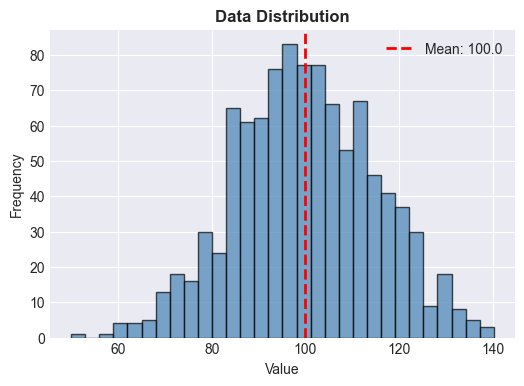

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import warnings
warnings.filterwarnings('ignore')

print(f"Matplotlib Version: {plt.matplotlib.__version__}")
print(f"Seaborn Version: {sns.__version__}")

# Set style for better-looking plots
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Create comprehensive visualization
fig, ax1 = plt.subplots(figsize=(6, 4))  # creates its own figure

# 1. Distribution Plot
data = np.random.normal(100, 15, 1000)
ax1.hist(data, bins=30, alpha=0.7, color='steelblue', edgecolor='black')
ax1.axvline(data.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {data.mean():.1f}')
ax1.set_title('Data Distribution', fontweight='bold')
ax1.set_xlabel('Value')
ax1.set_ylabel('Frequency')
ax1.legend()

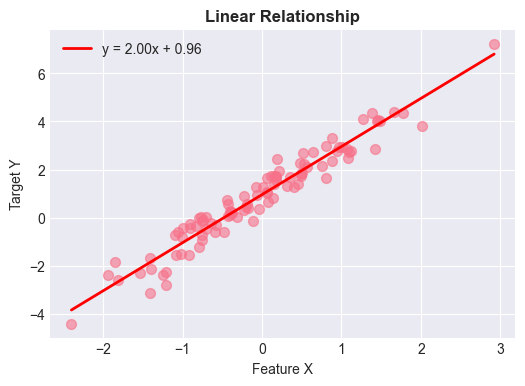

In [20]:
# 2. Scatter with Regression
fig, ax2 = plt.subplots(figsize=(6, 4))
x = np.random.randn(100)
y = 2 * x + 1 + np.random.randn(100) * 0.5
ax2.scatter(x, y, alpha=0.6, s=50)
z = np.polyfit(x, y, 1)
p = np.poly1d(z)
ax2.plot(sorted(x), p(sorted(x)), "r-", linewidth=2, label=f'y = {z[0]:.2f}x + {z[1]:.2f}')
ax2.set_title('Linear Relationship', fontweight='bold')
ax2.set_xlabel('Feature X')
ax2.set_ylabel('Target Y')
ax2.legend()

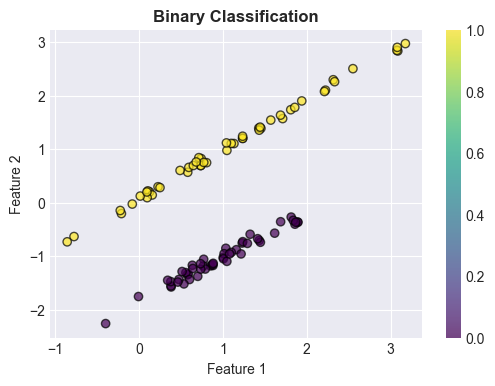

In [21]:
# 3. Classification Visualization
fig, ax3 = plt.subplots(figsize=(6, 4))
from sklearn.datasets import make_classification
X, y = make_classification(n_samples=100, n_features=2, n_redundant=0,
                          n_informative=2, n_clusters_per_class=1, random_state=42)
scatter = ax3.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', alpha=0.7, edgecolors='black')
ax3.set_title('Binary Classification', fontweight='bold')
ax3.set_xlabel('Feature 1')
ax3.set_ylabel('Feature 2')
plt.colorbar(scatter, ax=ax3)

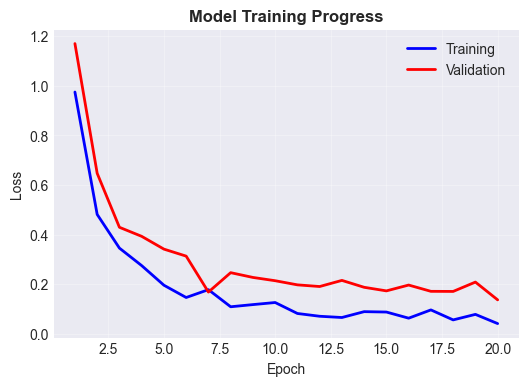

In [22]:
# 4. Training Curves
fig, ax4 = plt.subplots(figsize=(6, 4))
epochs = np.arange(1, 21)
train_loss = 1 / epochs + np.random.normal(0, 0.02, 20)
val_loss = 1 / epochs + 0.1 + np.random.normal(0, 0.03, 20)
ax4.plot(epochs, train_loss, 'b-', linewidth=2, label='Training')
ax4.plot(epochs, val_loss, 'r-', linewidth=2, label='Validation')
ax4.set_title('Model Training Progress', fontweight='bold')
ax4.set_xlabel('Epoch')
ax4.set_ylabel('Loss')
ax4.legend()
ax4.grid(alpha=0.3)

Text(0.5, 1.0, 'Model Performance')

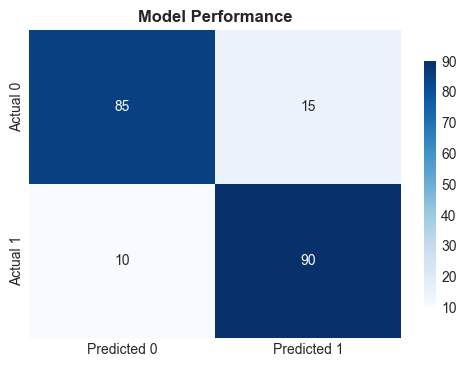

In [23]:
# 5. Confusion Matrix
fig, ax5 = plt.subplots(figsize=(6, 4))
confusion_matrix = np.array([[85, 15], [10, 90]])
sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'], ax=ax5, cbar_kws={'shrink': 0.8})
ax5.set_title('Model Performance', fontweight='bold')

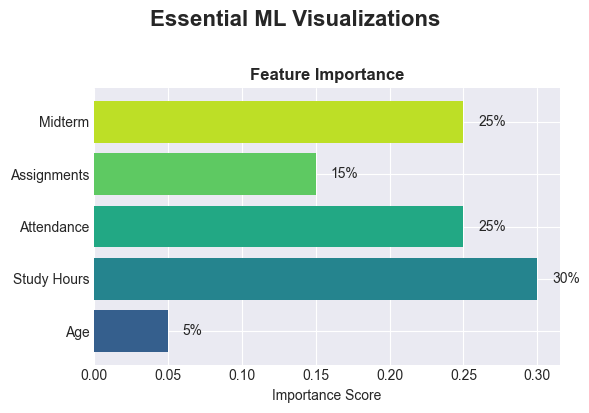

In [24]:
# 6. Feature Importance
fig, ax6 = plt.subplots(figsize=(6, 4))
features = ['Age', 'Study Hours', 'Attendance', 'Assignments', 'Midterm']
importance = [0.05, 0.30, 0.25, 0.15, 0.25]
colors = plt.cm.viridis(np.linspace(0.3, 0.9, len(features)))
bars = ax6.barh(features, importance, color=colors)
ax6.set_title('Feature Importance', fontweight='bold')
ax6.set_xlabel('Importance Score')
for bar, val in zip(bars, importance):
    ax6.text(val + 0.01, bar.get_y() + bar.get_height()/2, 
            f'{val:.0%}', va='center')

plt.suptitle('Essential ML Visualizations', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Scikit-learn: Your ML Swiss Army Knife

Scikit-learn provides battle-tested implementations of all classical ML algorithms with a consistent, simple API.


In [25]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import sklearn

print(f"Scikit-learn Version: {sklearn.__version__}")

# Generate a classification dataset
from sklearn.datasets import make_classification
X, y = make_classification(
    n_samples=500,
    n_features=10,
    n_informative=7,
    n_redundant=3,
    n_classes=2,
    random_state=42
)

SCIKIT-LEARN: Complete ML Pipeline
Version: 1.6.1

📊 DATASET
----------------------------------------
Samples: 500
Features: 10
Classes: [0 1]
Class distribution: [251 249]

🔄 DATA SPLITTING
----------------------------------------
Training set: 400 samples
Test set: 100 samples

⚙️ PREPROCESSING
----------------------------------------
Feature scaling applied (StandardScaler)
Mean after scaling: -0.000
Std after scaling: 1.000

🎯 MODEL TRAINING
----------------------------------------
Model: Random Forest with 100 trees

📈 PERFORMANCE
----------------------------------------
Training accuracy: 1.000
Testing accuracy: 0.860

5-Fold Cross-validation:
  Mean: 0.895
  Std: 0.019

🎯 DETAILED RESULTS
----------------------------------------
Confusion Matrix:
[[39  7]
 [ 7 47]]

Top 3 Important Features:
  1. Feature 9: 0.236
  2. Feature 0: 0.143
  3. Feature 1: 0.107


### Dataset Statistics

In [ ]:
print(f"Samples: {X.shape[0]}")
print(f"Features: {X.shape[1]}")
print(f"Classes: {np.unique(y)}")
print(f"Class distribution: {np.bincount(y)}")

### Data Splitting

In [ ]:
# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

### Preprocessing

In [ ]:
# Preprocessing
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Feature scaling applied (StandardScaler)")
print(f"Mean after scaling: {X_train_scaled.mean():.3f}")
print(f"Std after scaling: {X_train_scaled.std():.3f}")

### Model Training

In [ ]:
# Train model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train_scaled, y_train)
print(f"Model: Random Forest with 100 trees")

### Performance Evaluation

In [ ]:
# Evaluate
train_score = model.score(X_train_scaled, y_train)
test_score = model.score(X_test_scaled, y_test)

print(f"Training accuracy: {train_score:.3f}")
print(f"Testing accuracy: {test_score:.3f}")

# Cross-validation
cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=5)
print(f"\n5-Fold Cross-validation:")
print(f"  Mean: {cv_scores.mean():.3f}")
print(f"  Std: {cv_scores.std():.3f}")

### Detailed Results

In [ ]:
# Predictions
y_pred = model.predict(X_test_scaled)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Feature importance
importance = model.feature_importances_
top_3 = np.argsort(importance)[-3:][::-1]
print(f"\nTop 3 Important Features:")
for i, idx in enumerate(top_3, 1):
    print(f"  {i}. Feature {idx}: {importance[idx]:.3f}")

### PyTorch: Deep Learning Power

PyTorch enables you to build and train neural networks, from simple MLPs to complex architectures like transformers.


In [26]:
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    
    print(f"PyTorch Version: {torch.__version__}")
    
    # Check hardware acceleration
    print(f"\nHardware:")
    print(f"  CUDA available: {torch.cuda.is_available()}")
    print(f"  MPS available (Mac M1/M2): {torch.backends.mps.is_available()}")
    
    # Simple neural network
    class SimpleNet(nn.Module):
        def __init__(self):
            super(SimpleNet, self).__init__()
            self.fc1 = nn.Linear(10, 32)
            self.fc2 = nn.Linear(32, 16)
            self.fc3 = nn.Linear(16, 2)
            
        def forward(self, x):
            x = F.relu(self.fc1(x))
            x = F.relu(self.fc2(x))
            x = self.fc3(x)
            return x
    
    # Create model
    model = SimpleNet()
    
    print("\nNeural Network Created:")
    param_count = sum(p.numel() for p in model.parameters())
    print(f"  Total parameters: {param_count:,}")
    
    # Test forward pass
    test_input = torch.randn(1, 10)
    output = model(test_input)
    print(f"  Input shape: {test_input.shape}")
    print(f"  Output shape: {output.shape}")
    print(f"  Output: {output.data.numpy()[0]}")
    
    print("\nPyTorch is ready for deep learning!")
    
except ImportError as e:
    print("PyTorch not installed or not working properly")
    print(f"Error: {e}")
    print("\nTo install PyTorch, run:")
    print("pip install torch torchvision torchaudio")

PYTORCH: Deep Learning Framework
Version: 2.7.1

💻 Hardware:
  CUDA available: False
  MPS available (Mac M1/M2): True

🧠 Neural Network Created:
  Total parameters: 914
  Input shape: torch.Size([1, 10])
  Output shape: torch.Size([1, 2])
  Output: [-0.29522833  0.11840338]

✅ PyTorch is ready for deep learning!


## Part 3: Complete Environment Verification

Let's run a comprehensive check to ensure all components are properly installed and working together.


In [28]:
import sys
import importlib
from pathlib import Path

# System info
print("System Information")
print("-" * 40)
print(f"Python: {sys.version.split()[0]}")
print(f"Location: {sys.executable}")
print(f"Virtual Env: {'Yes' if 'ml_lectures_env' in sys.executable else 'No'}")

# Check current directory
current_dir = Path.cwd()
print(f"Current Directory: {current_dir.name}")

# Core packages check
print("\nPackage Status")
print("-" * 40)

packages = {
    'Core': {
        'numpy': None,
        'pandas': None,
        'matplotlib': 'matplotlib',
        'seaborn': None,
        'scipy': None,
    },
    'ML': {
        'sklearn': 'scikit-learn',
    },
    'Jupyter': {
        'IPython': None,
        'notebook': None,
        'ipykernel': None,
    },
    'Utilities': {
        'tqdm': None,
        'requests': None,
        'plotly': None,
    }
}

all_good = True
installed_count = 0
total_count = 0

for category, pkg_dict in packages.items():
    print(f"\n{category}:")
    for package, display_name in pkg_dict.items():
        total_count += 1
        try:
            module = importlib.import_module(package)
            version = getattr(module, '__version__', 'installed')
            print(f"  {package:12} {version}")
            installed_count += 1
        except ImportError:
            if display_name == '(optional)':
                print(f"  {package:12} (optional - not installed)")
            else:
                print(f"  {package:12} NOT INSTALLED")
                all_good = False

# Summary
print("\n" + "=" * 60)
print("SUMMARY")
print("=" * 60)

success_rate = (installed_count / total_count) * 100

if all_good:
    print("All required packages are installed!")
    print(f"Status: {installed_count}/{total_count} packages installed")
    print("You're ready to start the course!")
elif success_rate > 80:
    print(f"Most packages are installed ({installed_count}/{total_count})")
    print("Some optional packages are missing, but you can proceed")
else:
    print(f"Some required packages are missing ({installed_count}/{total_count})")
    print("Please run: pip install -r requirements.txt")

print("\n" + "=" * 60)

COMPREHENSIVE ENVIRONMENT CHECK

🖥️ SYSTEM INFORMATION
----------------------------------------
Python: 3.9.6
Location: /Users/ming/Dropbox/learn-ml-by-building/ml_lectures_env/bin/python
Virtual Env: Yes ✅
Current Directory: Lecture 0 Environment Setup

📦 PACKAGE STATUS
----------------------------------------

Core:
  ✅ numpy        2.0.2
  ✅ pandas       2.3.1
  ✅ matplotlib   3.9.4
  ✅ seaborn      0.13.2
  ✅ scipy        1.13.1

ML:
  ✅ sklearn      1.6.1

Jupyter:
  ✅ IPython      8.18.1
  ✅ notebook     6.5.7
  ✅ ipykernel    6.29.5

Utilities:
  ✅ tqdm         4.67.1
  ✅ requests     2.32.4
  ✅ plotly       6.2.0

SUMMARY
🎉 PERFECT! All required packages are installed!
📊 Status: 12/12 packages installed
🚀 You're ready to start the course!



## Part 4: Quick ML Workflow Demo

Let's run through a complete mini ML project to confirm everything works together!

In [ ]:
# Complete mini ML project: Iris classification
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import warnings
warnings.filterwarnings('ignore')

### 1. Load Data

In [29]:
iris = load_iris()
X, y = iris.data, iris.target
feature_names = iris.feature_names
target_names = iris.target_names

print(f"Dataset: {X.shape[0]} samples, {X.shape[1]} features")
print(f"Features: {feature_names}")
print(f"Classes: {target_names}")

MINI PROJECT: Iris Flower Classification

1️⃣ LOADING DATA
Dataset: 150 samples, 4 features
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: ['setosa' 'versicolor' 'virginica']


### 2. Prepare Data

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(f"Training: {len(X_train)} samples")
print(f"Testing: {len(X_test)} samples")


2️⃣ PREPARING DATA
Training: 105 samples
Testing: 45 samples


### 3. Train Model

In [31]:
model = RandomForestClassifier(n_estimators=50, random_state=42)
model.fit(X_train_scaled, y_train)
print("Model: Random Forest Classifier")
print(f"Trees: 50")


3️⃣ TRAINING MODEL
Model: Random Forest Classifier
Trees: 50


### 4. Evaluate

In [32]:
y_pred = model.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2%}")


4️⃣ EVALUATION
Accuracy: 100.00%


### 5. Visualize Results


5️⃣ VISUALIZATION


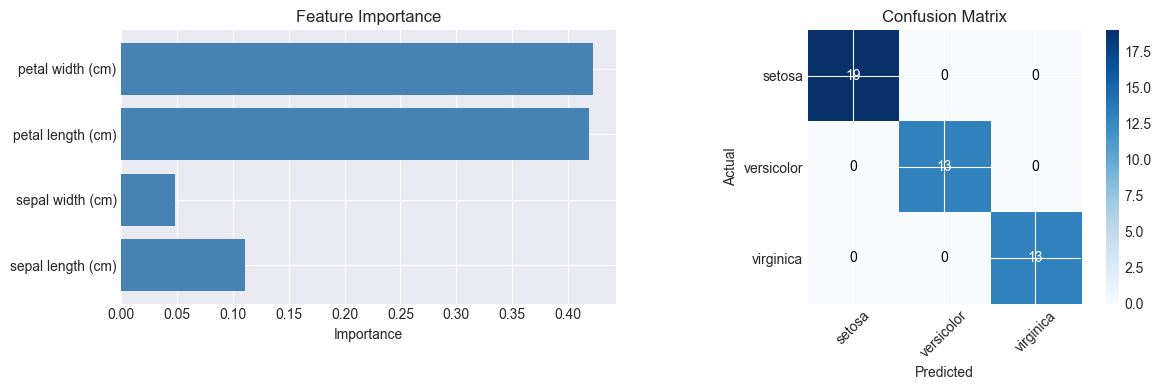


✅ Complete ML pipeline executed successfully!
🎉 Your environment is perfectly configured for the course!


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Feature importance
importance = model.feature_importances_
axes[0].barh(range(len(importance)), importance, color='steelblue')
axes[0].set_yticks(range(len(feature_names)))
axes[0].set_yticklabels(feature_names)
axes[0].set_xlabel('Importance')
axes[0].set_title('Feature Importance')

# Predictions vs Actual
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
im = axes[1].imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')
axes[1].set_title('Confusion Matrix')
axes[1].set_xticks([0, 1, 2])
axes[1].set_yticks([0, 1, 2])
axes[1].set_xticklabels(target_names, rotation=45)
axes[1].set_yticklabels(target_names)

# Add text annotations
for i in range(3):
    for j in range(3):
        axes[1].text(j, i, str(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")

plt.colorbar(im, ax=axes[1])
plt.tight_layout()
plt.show()

print("\nComplete ML pipeline executed successfully!")
print("Your environment is perfectly configured for the course!")

## 🔧 Part 5: Troubleshooting Within Jupyter

### Common Issues and Solutions

#### Package Import Errors

If you get `ModuleNotFoundError`:
```python
# Check if package is installed
!pip list | grep package_name

# Install missing package
!pip install package_name
```

#### Memory Issues
- Restart kernel: Kernel → Restart
- Clear outputs: Cell → All Output → Clear

#### Jupyter Issues
- Kernel died: Usually memory issue, restart kernel
- Slow performance: Close other notebooks, clear outputs

#### Package Version Conflicts
```python
# Check package version
import package
print(package.__version__)

# Upgrade package
!pip install --upgrade package_name
```

### Daily Workflow Reminder

```bash
# 1. Navigate to project
cd path/to/learn-ml-by-building

# 2. Activate environment
source ml_lectures_env/bin/activate     # Mac/Linux
ml_lectures_env\Scripts\activate         # Windows

# 3. Start Jupyter
jupyter notebook

# 4. Open lecture notebook and learn!
```

### Tips for Success

1. **Run code cells sequentially** - Order matters!
2. **Experiment freely** - Change parameters and see what happens
3. **Read error messages** - They're more helpful than you think
4. **Take notes** - Create your own summary notebooks
5. **Practice daily** - Even 30 minutes makes a difference